# Miniproyecto 2

En este Jupyter Notebook pueden implementar los códigos necesarios para resolver el **Miniproyecto 2**.

**Importante:** Recuerden que, como grupo, deben **adjuntar el código** en su entrega. En caso de que desarrollen parte del trabajo en este notebook pero **no lo incluyan en la entrega**, **toda la sección de calificación correspondiente al código será evaluada con cero**.

Tengan en cuenta que Coursera utiliza recursos compartidos entre todos los grupos, por lo tanto, si hay muchos equipos trabajando al mismo tiempo, los procesos pueden demorar más de lo previsto.

Pueden agregar todas las celdas de código que consideren necesarias para resolver el miniproyecto. **No hay un límite en este aspecto.**

# 1. Introducción y contexto

El objetivo es clasificar reseñas de películas de IMDb como positivas o negativas mediante una red neuronal recurrente. Cada reseña es una secuencia de palabras y recibe una sola etiqueta de sentimiento.

La organización del notebook y parte del desarrollo del taller se adaptan de los laboratorios de la semana 4.

# 2. Importar y acondicionar datos

Leemos el CSV comprimido y revisamos las columnas `text` (reseña) y `label` (etiqueta numérica).

In [1]:
# Celda con la importación de librerías

import copy
import re
from collections import Counter
from html import unescape
from pathlib import Path
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader

# Sklearn
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Inicialización de semillas
SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# Dispositivo de cómputo (usa GPU si está disponible)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo utilizado: {device}")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
    print(f"Hilos de CPU: {torch.get_num_threads()}")

Dispositivo utilizado: cpu
Hilos de CPU: 4


In [2]:
# Parámetros generales del experimento

MAX_VOCABULARIO = 20_000
PAD_ID = 0
UNK_ID = 1
DIM_EMBEDDING = 64
HIDDEN_SIZE = 64
TAM_LOTE = 32
LEARNING_RATE = 1e-3
N_EPOCHS = 5
PATIENCE = 2

Trabajamos en un repositorio de GitHub para facilitar el trabajo en equipo. El siguiente bloque busca el archivo comprimido desde la raíz del repositorio o desde la carpeta del microproyecto y lee el CSV directamente desde el ZIP. Este código puede no funcionar si se ejecuta este notebook de forma local.

In [3]:
# Ruta para ejecutar desde microproyecto2/ o desde la raíz del repositorio.
ruta_datos = Path('datos/movie.csv.zip')
if not ruta_datos.is_file():
    ruta_datos = Path('microproyecto2') / ruta_datos

resenas = pd.read_csv(ruta_datos)
resenas.info()
display(resenas.head(3))
display(resenas['label'].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    40000 non-null  str  
 1   label   40000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 625.1 KB


,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0


label
0    20019
1    19981
Name: count, dtype: int64

## 2.1. Duplicados y división de los datos

Antes de dividir el dataset verificamos si algún texto idéntico tiene etiquetas distintas. Conservamos una sola fila por texto exacto para evitar que una misma reseña aparezca en varios conjuntos.

Hacemos una división 70/15/15 para entrenamiento, validación y prueba. La estratificación mantiene una proporción similar de etiquetas en cada conjunto. El vocabulario se ajustará solo con entrenamiento.

In [4]:
etiquetas_por_texto = resenas.groupby('text')['label'].nunique()
if etiquetas_por_texto.gt(1).any():
    raise ValueError('Hay textos idénticos con etiquetas distintas.')

resenas_unicas = resenas.drop_duplicates(subset='text').reset_index(drop=True)
print(f'Reseñas originales: {len(resenas):,}')
print(f'Repeticiones eliminadas: {len(resenas) - len(resenas_unicas):,}')
print(f'Reseñas únicas: {len(resenas_unicas):,}')

Reseñas originales: 40,000
Repeticiones eliminadas: 277
Reseñas únicas: 39,723


In [5]:
def split_data(datos, seed):
    '''
    Divide las reseñas en entrenamiento (70 %), validación (15 %) y prueba (15 %)
    manteniendo la proporción de las etiquetas.

    Parámetros de entrada:
    datos = DataFrame con las columnas text y label
    seed = semilla de la división

    Salida:
    train_df, val_df, test_df = DataFrames de los tres conjuntos
    '''
    train_df, restantes = train_test_split(
        datos, test_size=0.30, stratify=datos["label"], random_state=seed
    )
    val_df, test_df = train_test_split(
        restantes, test_size=0.50, stratify=restantes["label"], random_state=seed
    )
    return train_df, val_df, test_df


train_df, val_df, test_df = split_data(resenas_unicas, SEMILLA)

for nombre, conjunto in [("Entrenamiento", train_df), ("Validación", val_df), ("Prueba", test_df)]:
    conteos = conjunto["label"].value_counts().sort_index().to_dict()
    print(f"{nombre}: {len(conjunto):,} reseñas | conteo por etiqueta: {conteos}")

Entrenamiento: 27,806 reseñas | conteo por etiqueta: {0: 13870, 1: 13936}
Validación: 5,958 reseñas | conteo por etiqueta: {0: 2972, 1: 2986}
Prueba: 5,959 reseñas | conteo por etiqueta: {0: 2973, 1: 2986}


## 2.2. Limpiar y tokenizar

Decodificamos entidades HTML, sustituimos etiquetas como `<br />` por espacios y pasamos el texto a minúsculas. Conservamos palabras, números, contracciones como `didn't` y los signos `!` y `?`, que pueden aportar información sobre el sentimiento.

In [6]:
def tokenizar(texto):
    '''
    Limpia una reseña y la divide en tokens.

    Parámetros de entrada:
    texto = reseña original

    Salida:
    tokens = lista de palabras, números y signos de exclamación e interrogación
    '''
    texto = unescape(texto).lower().replace("’", "'")
    texto = re.sub(r"<[^>]+>", " ", texto)
    return re.findall(r"\w+(?:'\w+)*|[!?]", texto)

## 2.3. Construir el vocabulario y convertir a índices

Como en el laboratorio al ajustar el escalador, usamos solo entrenamiento para aprender la transformación. Tomamos los tokens más frecuentes hasta un máximo inicial de 20.000 entradas, incluidos `<PAD>` (relleno de lotes) y `<UNK>` (tokens fuera del vocabulario). Aplicamos el mismo diccionario a los tres conjuntos.

In [7]:
frecuencias = Counter()
for texto in train_df["text"]:
    frecuencias.update(tokenizar(texto))

vocabulario = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for token, _ in frecuencias.most_common(MAX_VOCABULARIO - len(vocabulario)):
    vocabulario[token] = len(vocabulario)

def codificar(tokens, vocabulario):
    '''
    Convierte los tokens de una reseña en índices del vocabulario.
    '''
    return [vocabulario.get(token, UNK_ID) for token in tokens]

print(f"Tamaño del vocabulario: {len(vocabulario):,}")

Tamaño del vocabulario: 20,000


In [8]:
train_ids = [codificar(tokenizar(texto), vocabulario) for texto in train_df["text"]]
val_ids = [codificar(tokenizar(texto), vocabulario) for texto in val_df["text"]]
test_ids = [codificar(tokenizar(texto), vocabulario) for texto in test_df["text"]]

In [9]:
texto_ejemplo = train_df["text"].iloc[0]
tokens_ejemplo = tokenizar(texto_ejemplo)
ids_ejemplo = train_ids[0]

print(f"Texto original (primeros 250 caracteres):\n{texto_ejemplo[:250]}")
display(pd.DataFrame({"token": tokens_ejemplo[:12], "índice": ids_ejemplo[:12]}))

Texto original (primeros 250 caracteres):
Well...I like Patricia Kaas. She is a beautiful lady and an extremely gifted and versatile singer. Her acting in this film is more than competent and from my point of view about the only redeeming feauture of this film. She very gently captures the e


,token,índice
0,well,70
1,i,10
2,like,38
3,patricia,4989
4,kaas,16975
5,she,61
6,is,7
7,a,4
8,beautiful,311
9,lady,759


## 2.4. De índices a embeddings

`nn.Embedding` es una tabla entrenable con una fila por entrada del vocabulario. Cada índice recupera su fila, un vector de 64 componentes en esta configuración inicial. La tabla empieza con pesos aleatorios y aprenderá durante el entrenamiento del clasificador. Con una reseña de longitud $T$, la entrada tiene forma $(1, T)$ y la salida $(1, T, 64)$.

In [10]:
embedding = nn.Embedding(len(vocabulario), DIM_EMBEDDING, padding_idx=PAD_ID).to(device)

entrada = torch.tensor(ids_ejemplo, dtype=torch.long).unsqueeze(0).to(device)
with torch.no_grad():
    vectores = embedding(entrada)

print("Forma de los índices:", tuple(entrada.shape))
print("Forma de los embeddings:", tuple(vectores.shape))
print(f"Primer token: {tokens_ejemplo[0]!r}, índice: {ids_ejemplo[0]}")
print("Primeras 6 componentes de su vector:", vectores[0, 0, :6])

Forma de los índices: (1, 169)
Forma de los embeddings: (1, 169, 64)
Primer token: 'well', índice: 70
Primeras 6 componentes de su vector: tensor([ 0.9625,  0.0453, -2.0377, -1.0923, -0.1738, -1.0654])


## 2.5. Agrupar reseñas en lotes

Retomamos el `DataLoader` del laboratorio. Como las reseñas tienen longitudes distintas, le pasamos una función `collate_fn` que agrega `<PAD>` al final de las reseñas cortas hasta igualar la longitud de la más larga del lote.

Cada lote devuelve los índices con forma $(B, T)$, las longitudes reales con forma $(B,)$ y las etiquetas con forma $(B,)$. Aquí $B$ es el número de reseñas y $T$ es la longitud máxima del lote. Las longitudes reales identifican el último token de cada reseña.

In [11]:
def armar_lote(lote):
    '''
    Construye un lote con relleno para reseñas de distinta longitud.

    Parámetros de entrada:
    lote = lista de pares (secuencia de índices, etiqueta)

    Salida:
    indices = tensor (B, T) con relleno al final de cada reseña
    longitudes = número de tokens reales de cada reseña
    etiquetas = tensor con las etiquetas binarias
    '''
    secuencias, etiquetas = zip(*lote)
    secuencias = [torch.tensor(ids, dtype=torch.long) for ids in secuencias]
    longitudes = torch.tensor([len(ids) for ids in secuencias], dtype=torch.long)
    indices = pad_sequence(secuencias, batch_first=True, padding_value=PAD_ID)
    etiquetas = torch.tensor(etiquetas, dtype=torch.float32)
    return indices, longitudes, etiquetas

In [12]:
# Preparar los conjuntos para el DataLoader
train_dataset = list(zip(train_ids, train_df["label"]))
val_dataset = list(zip(val_ids, val_df["label"]))
test_dataset = list(zip(test_ids, test_df["label"]))

train_loader = DataLoader(
    train_dataset, batch_size=TAM_LOTE, shuffle=True, collate_fn=armar_lote
)
val_loader = DataLoader(
    val_dataset, batch_size=TAM_LOTE, shuffle=False, collate_fn=armar_lote
)
test_loader = DataLoader(
    test_dataset, batch_size=TAM_LOTE, shuffle=False, collate_fn=armar_lote
)

In [13]:
indices_lote, longitudes_lote, etiquetas_lote = next(iter(val_loader))

print("Forma de los índices:", tuple(indices_lote.shape))
print("Forma de las longitudes:", tuple(longitudes_lote.shape))
print("Forma de las etiquetas:", tuple(etiquetas_lote.shape))
print("Longitudes de las primeras 5 reseñas:", longitudes_lote[:5].tolist())

pos = longitudes_lote.argmin().item()
longitud = longitudes_lote[pos].item()
relleno = indices_lote.shape[1] - longitud
print(f"Reseña más corta del lote: {longitud} tokens y {relleno} posiciones de relleno.")
print("Primeros 5 índices del relleno:", indices_lote[pos, longitud:longitud + 5].tolist())

Forma de los índices: (32, 526)
Forma de las longitudes: (32,)
Forma de las etiquetas: (32,)
Longitudes de las primeras 5 reseñas: [148, 70, 133, 460, 153]
Reseña más corta del lote: 60 tokens y 466 posiciones de relleno.
Primeros 5 índices del relleno: [0, 0, 0, 0, 0]


# 3. Clasificación con una red LSTM

El `DataLoader` entrega un lote de índices, las longitudes reales y las etiquetas. La capa de embedding transforma los índices en vectores de 64 componentes. La LSTM lee esos vectores en orden y mantiene un estado oculto de 64 componentes por reseña.

La capa lineal usa el estado oculto del último token real de cada reseña. En CUDA usamos `pack_padded_sequence`. En CPU ejecutamos la LSTM sobre el lote rectangular y seleccionamos la salida en `longitud - 1`, antes del relleno. Como la LSTM es unidireccional, ambos caminos usan el mismo contexto para calcular el logit.

In [14]:
class LSTMClassifier(nn.Module):
    '''
    Clasificador binario de reseñas basado en una capa LSTM.
    '''
    def __init__(self, vocab_size, embedding_dim, hidden_size, padding_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, indices, longitudes):
        embeddings = self.embedding(indices)

        if embeddings.device.type == "cpu":
            # Usar la salida del último token real para cada reseña.
            salidas, _ = self.lstm(embeddings)
            filas = torch.arange(indices.size(0))
            estado_final = salidas[filas, longitudes - 1]
        else:
            secuencias = pack_padded_sequence(
                embeddings, longitudes.cpu(), batch_first=True, enforce_sorted=False
            )
            _, (h_n, _) = self.lstm(secuencias)
            estado_final = h_n[-1]

        logits = self.output_layer(estado_final)
        return logits.squeeze(-1)


model = LSTMClassifier(len(vocabulario), DIM_EMBEDDING, HIDDEN_SIZE, PAD_ID).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nNúmero total de parámetros entrenables: {n_params:,}")

LSTMClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)

Número total de parámetros entrenables: 1,313,345


Usamos Adam y `BCEWithLogitsLoss` para comparar los logits con las etiquetas binarias. La función de pérdida incorpora la sigmoide. Cuando queremos mostrar la probabilidad de la etiqueta 1, aplicamos `torch.sigmoid` al logit.

In [15]:
# Configuración del optimizador y de la función de pérdida
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()

In [16]:
# Comprobar la forma de la salida del modelo con un lote del DataLoader
X_batch, longitudes_batch, y_batch = next(iter(val_loader))
X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

model.eval()
with torch.no_grad():
    logits = model(X_batch, longitudes_batch)
    loss = criterion(logits, y_batch)
    probabilidades = torch.sigmoid(logits)

print("Forma del lote de índices:", tuple(X_batch.shape))
print("Forma de los logits:", tuple(logits.shape))
print("Forma de las etiquetas:", tuple(y_batch.shape))
print(f"Pérdida del lote con el modelo inicial: {loss.item():.4f}")
print("Probabilidades de la etiqueta 1 (primeras 5):", probabilidades[:5].cpu())

Forma del lote de índices: (32, 526)
Forma de los logits: (32,)
Forma de las etiquetas: (32,)
Pérdida del lote con el modelo inicial: 0.7028
Probabilidades de la etiqueta 1 (primeras 5): tensor([0.4792, 0.4786, 0.4794, 0.4806, 0.4654])


## 3.1. Entrenamiento y validación

En cada época, recorremos `train_loader` para actualizar los pesos. Luego recorremos `val_loader` en modo de evaluación y sin calcular gradientes. Para obtener la pérdida promedio por reseña, ponderamos la pérdida de cada lote por su tamaño.

Guardamos los pesos de la época con menor pérdida de validación. Si la pérdida pasa `PATIENCE` épocas consecutivas sin mejorar, detenemos el entrenamiento y recuperamos esos pesos. La primera corrida permite hasta `N_EPOCHS` épocas.

In [17]:
def evaluate_model(model, data_loader, criterion):
    '''
    Calcula la pérdida promedio por reseña de un DataLoader en modo evaluación.
    '''
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for X_batch, longitudes_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch, longitudes_batch)
            loss = criterion(logits, y_batch)
            running_loss += loss.item() * X_batch.size(0)

    return running_loss / len(data_loader.dataset)

In [18]:
def train_model(model, train_loader, val_loader, optimizer, criterion, n_epochs, patience):
    '''
    Entrena la LSTM por lotes y restaura los pesos de la mejor época.

    Parámetros de entrada:
    train_loader, val_loader = lotes de entrenamiento y validación
    optimizer, criterion = optimizador y función de pérdida
    n_epochs, patience = máximo de épocas y tolerancia sin mejora

    Salida:
    history = pérdidas por época y número de la mejor época de validación
    '''
    start = time()
    history = {"loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_model_state = None
    epochs_no_improve = 0

    for epoch in range(n_epochs):
        # Fase de entrenamiento
        model.train()
        running_loss = 0.0
        for X_batch, longitudes_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(X_batch, longitudes_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        # Fase de validación
        val_loss = evaluate_model(model, val_loader, criterion)
        if not np.isfinite(val_loss):
            raise RuntimeError("La pérdida de validación dejó de ser finita.")

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Época {epoch + 1}/{n_epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

        # Parada temprana y copia de los mejores pesos
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch + 1
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Parada temprana en la época {epoch + 1}.")
                break

    model.load_state_dict(best_model_state)
    print(f"Mejor época: {history['best_epoch']} - val_loss: {best_val_loss:.4f}")
    print(f"Tiempo de entrenamiento: {(time() - start) / 60:.2f} min")
    return history

In [19]:
# Ejecutar el entrenamiento con todos los lotes de entrenamiento y validación
history = train_model(
    model, train_loader, val_loader, optimizer, criterion,
    n_epochs=N_EPOCHS, patience=PATIENCE
)

Época 1/5 - loss: 0.5859 - val_loss: 0.5767


Época 2/5 - loss: 0.4674 - val_loss: 0.4406


Época 3/5 - loss: 0.4127 - val_loss: 0.4478


Época 4/5 - loss: 0.3248 - val_loss: 0.3541


Época 5/5 - loss: 0.2810 - val_loss: 0.3437
Mejor época: 5 - val_loss: 0.3437
Tiempo de entrenamiento: 5.50 min


## 3.2. Curvas de pérdida

Adaptamos `visualization_history` del laboratorio de RNN. Las épocas empiezan en 1 y la línea vertical marca la época con menor pérdida de validación, cuyos pesos se restauraron al terminar.

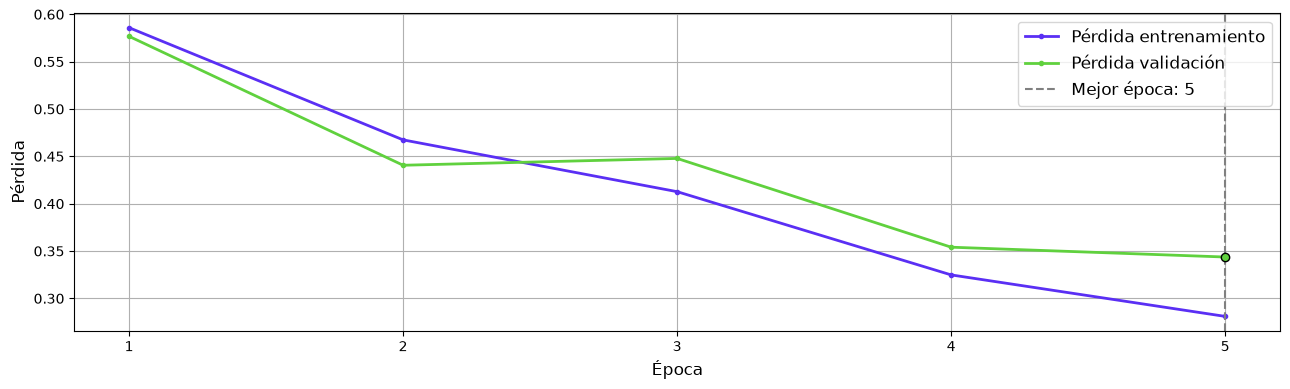

In [20]:
def visualization_history(resultsFit):
    """
    Grafica las pérdidas de entrenamiento y validación por época.
    Parámetros:
    resultsFit = diccionario con 'loss', 'val_loss' y 'best_epoch'
    """
    epochs = range(1, len(resultsFit['loss']) + 1)
    best_epoch = resultsFit['best_epoch']
    fig, axes = plt.subplots(1, 1, figsize=(13, 4))

    # Curvas de entrenamiento y validación
    axes.plot(epochs, resultsFit['loss'], '#5a2ff4', linestyle='-', marker='.',
              label='Pérdida entrenamiento', lw=2)
    axes.plot(epochs, resultsFit['val_loss'], '#60d13e', linestyle='-', marker='.',
              label='Pérdida validación', lw=2)

    # Marcar la época cuyos pesos se restauraron
    axes.axvline(best_epoch, color='gray', linestyle='--', label=f'Mejor época: {best_epoch}')
    axes.scatter(best_epoch, resultsFit['val_loss'][best_epoch - 1],
                 color='#60d13e', edgecolor='black', zorder=3)

    axes.set_xlabel('Época', fontsize=12)
    axes.set_ylabel('Pérdida', fontsize=12)
    axes.set_xticks(list(epochs))
    axes.grid()
    axes.legend(fontsize=12, loc='upper right')
    plt.tight_layout()
    plt.show()


visualization_history(history)

# 4. Evaluación en el conjunto de prueba

Usamos el modelo restaurado en la mejor época de validación. Para cada reseña, aplicamos la sigmoide al logit y asignamos la etiqueta 1 cuando la probabilidad es al menos 0,5. Calculamos *precision*, *recall* y *F1* por clase y su promedio macro, que da el mismo peso a ambas clases.

En este archivo la etiqueta 0 corresponde a reseñas negativas y la 1 a positivas. El reporte conserva los nombres numéricos del CSV. La [ficha de Kaggle enlazada en el enunciado](https://www.kaggle.com/datasets/yasserh/imdb-movie-ratings-sentiment-analysis) describe otro esquema de cinco clases, que no corresponde a este archivo binario.

In [21]:
# Obtener etiquetas y probabilidades en una pasada por test_loader
model.eval()
etiquetas_reales = []
probabilidades = []
running_loss = 0.0

with torch.no_grad():
    for X_batch, longitudes_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch, longitudes_batch)
        running_loss += criterion(logits, y_batch).item() * X_batch.size(0)
        etiquetas_reales.append(y_batch.cpu())
        probabilidades.append(torch.sigmoid(logits).cpu())

y_test = torch.cat(etiquetas_reales).numpy().astype(int)
prob_test = torch.cat(probabilidades).numpy()
y_pred = (prob_test >= 0.5).astype(int)
test_loss = running_loss / len(test_loader.dataset)

print(f"Reseñas evaluadas: {len(y_test):,}")
print(f"Pérdida de prueba: {test_loss:.4f}")

Reseñas evaluadas: 5,959
Pérdida de prueba: 0.3369


In [22]:
# Métricas de clasificación para cada etiqueta y promedio macro
reporte = classification_report(
    y_test, y_pred, labels=[0, 1], target_names=["Clase 0", "Clase 1"],
    output_dict=True, zero_division=0,
)
metricas = pd.DataFrame(reporte).T.loc[
    ["Clase 0", "Clase 1", "macro avg"], ["precision", "recall", "f1-score", "support"]
].rename(index={"macro avg": "Promedio macro"}, columns={"support": "Reseñas"})
metricas["Reseñas"] = metricas["Reseñas"].astype(int)
display(metricas.round(4))
print(f"Exactitud en prueba: {reporte['accuracy']:.4f}")

,precision,recall,f1-score,Reseñas
Clase 0,0.8937,0.8311,0.8613,2973
Clase 1,0.8428,0.9015,0.8712,2986
Promedio macro,0.8683,0.8663,0.8662,5959


Exactitud en prueba: 0.8664


In [23]:
# Filas: etiquetas reales. Columnas: etiquetas predichas.
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(
    matriz,
    index=pd.Index([0, 1], name="Etiqueta real"),
    columns=pd.Index([0, 1], name="Etiqueta predicha"),
))

Etiqueta predicha,0,1
Etiqueta real,,
0,2471,502
1,294,2692


## 4.1. Ejemplos de aciertos y errores

Para facilitar la lectura, mostramos una reseña breve de cada combinación de etiqueta real y predicción cuando hay casos en esa combinación. La probabilidad corresponde a la etiqueta 1.

In [24]:
for real, predicha in [(0, 0), (1, 1), (0, 1), (1, 0)]:
    coincidencias = np.flatnonzero((y_test == real) & (y_pred == predicha))
    if len(coincidencias) == 0:
        continue

    pos = min(coincidencias, key=lambda i: len(test_df["text"].iloc[i]))
    texto = re.sub(r"<[^>]+>", " ", unescape(test_df["text"].iloc[pos]))
    caso = "Acierto" if real == predicha else "Error"
    print(f"{caso} | Real: {real} | Predicha: {predicha} | P(clase 1): {prob_test[pos]:.3f}")
    print(f"{texto.strip()}\n")

Acierto | Real: 0 | Predicha: 0 | P(clase 1): 0.320
Unwatchable. You can't even make it past the first three minutes. And this is coming from a huge Adam Sandler fan!!1

Acierto | Real: 1 | Predicha: 1 | P(clase 1): 0.960
As usual, Sean Connery does a great job. Lawrence Fishburn is good, but I have a hard time not seeing him as Ike Turner.

Error | Real: 0 | Predicha: 1 | P(clase 1): 0.737
Read the book, forget the movie!

Error | Real: 1 | Predicha: 0 | P(clase 1): 0.174
What an amazing film. With very little dialogue, the whole story is told with glances and body language. Very involving almost voyeuristic. My only gripe is that it has not been released on video in Australia and is therefore only available on TV. What a waste.



De acuerdo con la gráfica de pérdida, podemos ver que la pérdida de entrenamiento bajó en cada época (de 0.5859 a 0.2810). En validación hubo un pequeño aumento entre las épocas 2 y 3 (pasó de 0.4406 a 0.4478), a la par que el modelo seguía mejorando en el entrenamiento. Esto podría ser una ligera señal de sobreajuste y se volvería preocupante de haber continuado la tendencia. Sin embargo, la pérdida de validación volvió a bajar en la época 4 y en la 5. Se eligió la época 5 porque fue la mejor de las cinco observadas según la validación, antes de mirar los resultados de prueba.

Al comparar el recall, vemos que el modelo identificó correctamente el 90.15 % de las reseñas de la clase 1 y el 83.11 % de las de la clase 0. Esto se refleja en la matriz de confusión: hubo 502 reseñas de la clase 0 clasificadas como 1 y 294 errores en el sentido contrario. Como las dos clases tenían casi el mismo número de reseñas, la diferencia también se mantiene al comparar sus tasas de error. A la vez, la precisión fue menor para la clase 1, porque entre las reseñas que el modelo asignó a esa clase hubo más predicciones incorrectas.

# 5. Comparación entre LSTM y GRU con varias semillas

Con una sola corrida no sabemos qué parte del resultado depende de la inicialización de los pesos y del orden de los lotes. Por eso repetimos el entrenamiento con tres semillas (0, 1 y 2) para dos arquitecturas: la LSTM de la sección 3 y una GRU con el mismo embedding y el mismo tamaño de estado oculto. La GRU tiene dos compuertas en lugar de tres y no guarda una celda de memoria aparte, así que tiene menos parámetros.

Los datos, el vocabulario, la división y los hiperparámetros no cambian. La semilla controla la inicialización y el orden de los lotes de entrenamiento. En cada corrida guardamos las pérdidas por época y las métricas en prueba con los pesos de la mejor época de validación.

In [25]:
class RNNClassifier(nn.Module):
    '''
    Clasificador binario de reseñas con una capa recurrente LSTM o GRU.

    Parámetros de entrada:
    tipo = "LSTM" o "GRU"
    vocab_size, embedding_dim, hidden_size, padding_idx = como en LSTMClassifier
    '''
    def __init__(self, tipo, vocab_size, embedding_dim, hidden_size, padding_idx):
        super().__init__()
        capas = {"LSTM": nn.LSTM, "GRU": nn.GRU}
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        self.rnn = capas[tipo](input_size=embedding_dim, hidden_size=hidden_size, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, indices, longitudes):
        embeddings = self.embedding(indices)

        if embeddings.device.type == "cpu":
            # Usar la salida del último token real para cada reseña.
            salidas, _ = self.rnn(embeddings)
            filas = torch.arange(indices.size(0))
            estado_final = salidas[filas, longitudes - 1]
        else:
            secuencias = pack_padded_sequence(
                embeddings, longitudes.cpu(), batch_first=True, enforce_sorted=False
            )
            _, h_n = self.rnn(secuencias)
            if isinstance(h_n, tuple):  # la LSTM devuelve (h_n, c_n)
                h_n = h_n[0]
            estado_final = h_n[-1]

        return self.output_layer(estado_final).squeeze(-1)


for tipo in ["LSTM", "GRU"]:
    modelo = RNNClassifier(tipo, len(vocabulario), DIM_EMBEDDING, HIDDEN_SIZE, PAD_ID)
    n_rnn = sum(p.numel() for p in modelo.rnn.parameters())
    n_total = sum(p.numel() for p in modelo.parameters())
    print(f"{tipo}: {n_total:,} parámetros en total, {n_rnn:,} en la capa recurrente")

LSTM: 1,313,345 parámetros en total, 33,280 en la capa recurrente
GRU: 1,305,025 parámetros en total, 24,960 en la capa recurrente


In [26]:
def predecir(model, data_loader, criterion):
    '''
    Calcula etiquetas reales, probabilidades de la etiqueta 1 y pérdida promedio.
    '''
    model.eval()
    etiquetas, probs = [], []
    running_loss = 0.0

    with torch.no_grad():
        for X_batch, longitudes_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch, longitudes_batch)
            running_loss += criterion(logits, y_batch).item() * X_batch.size(0)
            etiquetas.append(y_batch.cpu())
            probs.append(torch.sigmoid(logits).cpu())

    y_real = torch.cat(etiquetas).numpy().astype(int)
    return y_real, torch.cat(probs).numpy(), running_loss / len(data_loader.dataset)

In [27]:
# Entrenar cada arquitectura con cada semilla (puede tardar cerca de una hora en CPU)
SEMILLAS = [0, 1, 2]
ARQUITECTURAS = ["LSTM", "GRU"]

resultados = []
historias = {}

for tipo in ARQUITECTURAS:
    for semilla in SEMILLAS:
        print(f"\n=== {tipo} | semilla {semilla} ===")
        torch.manual_seed(semilla)
        np.random.seed(semilla)
        loader_semilla = DataLoader(
            train_dataset, batch_size=TAM_LOTE, shuffle=True, collate_fn=armar_lote,
            generator=torch.Generator().manual_seed(semilla),
        )
        modelo = RNNClassifier(tipo, len(vocabulario), DIM_EMBEDDING, HIDDEN_SIZE, PAD_ID).to(device)
        optimizador = optim.Adam(modelo.parameters(), lr=LEARNING_RATE)

        inicio = time()
        hist = train_model(
            modelo, loader_semilla, val_loader, optimizador, criterion,
            n_epochs=N_EPOCHS, patience=PATIENCE
        )
        minutos = (time() - inicio) / 60

        y_real, prob, perdida = predecir(modelo, test_loader, criterion)
        y_hat = (prob >= 0.5).astype(int)
        rep = classification_report(y_real, y_hat, labels=[0, 1], output_dict=True, zero_division=0)

        historias[(tipo, semilla)] = hist
        resultados.append({
            "Modelo": tipo,
            "Semilla": semilla,
            "Mejor época": hist["best_epoch"],
            "Pérdida val.": min(hist["val_loss"]),
            "Pérdida prueba": perdida,
            "Exactitud": rep["accuracy"],
            "F1 macro": rep["macro avg"]["f1-score"],
            "Precision 0": rep["0"]["precision"],
            "Recall 0": rep["0"]["recall"],
            "Precision 1": rep["1"]["precision"],
            "Recall 1": rep["1"]["recall"],
            "Predicciones 1 (%)": 100 * y_hat.mean(),
            "Minutos": minutos,
        })


=== LSTM | semilla 0 ===


Época 1/5 - loss: 0.6397 - val_loss: 0.6647


Época 2/5 - loss: 0.5572 - val_loss: 0.5497


Época 3/5 - loss: 0.3960 - val_loss: 0.3472


Época 4/5 - loss: 0.2700 - val_loss: 0.2974


Época 5/5 - loss: 0.2116 - val_loss: 0.2836
Mejor época: 5 - val_loss: 0.2836
Tiempo de entrenamiento: 6.51 min


... (26 outputs left out)

Época 2/5 - loss: 0.3734 - val_loss: 0.3272


Época 3/5 - loss: 0.2515 - val_loss: 0.2966


Época 4/5 - loss: 0.1857 - val_loss: 0.2680


Época 5/5 - loss: 0.1378 - val_loss: 0.2948
Mejor época: 4 - val_loss: 0.2680
Tiempo de entrenamiento: 16.81 min


## 5.1. Resultados por corrida y resumen

La primera tabla muestra cada corrida. La segunda resume cada arquitectura con el promedio ± la desviación estándar muestral de las tres semillas. Las métricas son de prueba, salvo la pérdida de validación de la mejor época.

In [28]:
tabla_corridas = pd.DataFrame(resultados)
display(tabla_corridas.round(4))

metricas_resumen = [
    "Exactitud", "F1 macro", "Precision 0", "Recall 0", "Precision 1", "Recall 1",
    "Pérdida val.", "Pérdida prueba", "Predicciones 1 (%)", "Mejor época", "Minutos",
]
media = tabla_corridas.groupby("Modelo")[metricas_resumen].mean().T
desviacion = tabla_corridas.groupby("Modelo")[metricas_resumen].std().T  # ddof = 1
resumen = media.round(4).astype(str) + " ± " + desviacion.round(4).astype(str)
display(resumen[ARQUITECTURAS])

,Modelo,Semilla,Mejor época,Pérdida val.,Pérdida prueba,Exactitud,F1 macro,Precision 0,Recall 0,Precision 1,Recall 1,Predicciones 1 (%),Minutos
0,LSTM,0,5,0.2836,0.2980,0.8809,0.8807,0.9069,0.8483,0.8581,0.9133,53.3311,6.5129
1,LSTM,1,4,0.2993,0.2974,0.8827,0.8827,0.8926,0.8695,0.8733,0.8958,51.4012,10.4934
2,LSTM,2,5,0.3359,0.3403,0.8565,0.8565,0.8570,0.8550,0.8560,0.8580,50.2265,13.7525
3,GRU,0,3,0.2564,0.2714,0.8862,0.8862,0.8791,0.8951,0.8936,0.8774,49.2029,20.0684
4,GRU,1,4,0.2749,0.2911,0.8859,0.8859,0.8949,0.8739,0.8773,0.8979,51.2838,17.2038
5,GRU,2,4,0.2680,0.2815,0.8874,0.8873,0.9134,0.8554,0.8646,0.9193,53.2808,16.8144


Modelo,LSTM,GRU
Exactitud,0.8734 ± 0.0146,0.8865 ± 0.0008
F1 macro,0.8733 ± 0.0146,0.8864 ± 0.0007
Precision 0,0.8855 ± 0.0257,0.8958 ± 0.0172
Recall 0,0.8576 ± 0.0108,0.8748 ± 0.0199
Precision 1,0.8625 ± 0.0095,0.8785 ± 0.0145
Recall 1,0.889 ± 0.0283,0.8982 ± 0.0209
Pérdida val.,0.3063 ± 0.0268,0.2664 ± 0.0093
Pérdida prueba,0.3119 ± 0.0246,0.2813 ± 0.0098
Predicciones 1 (%),51.653 ± 1.5675,51.2558 ± 2.0391
Mejor época,4.6667 ± 0.5774,3.6667 ± 0.5774


In [29]:
# Pérdidas por época de cada corrida
filas = []
for (tipo, semilla), hist in historias.items():
    for epoca, (perdida_ent, perdida_val) in enumerate(zip(hist["loss"], hist["val_loss"]), start=1):
        filas.append({"Modelo": tipo, "Semilla": semilla, "Época": epoca,
                      "loss": perdida_ent, "val_loss": perdida_val})
curvas = pd.DataFrame(filas)

for columna, nombre in [("loss", "entrenamiento"), ("val_loss", "validación")]:
    print(f"Pérdida de {nombre} por época:")
    display(curvas.pivot_table(index=["Modelo", "Semilla"], columns="Época", values=columna).round(4))

Pérdida de entrenamiento por época:


Época                1       2       3       4       5
Modelo Semilla                                        
GRU    0        0.6367  0.3507  0.2199  0.1589  0.1096
       1        0.5686  0.3724  0.2486  0.1826  0.1331
       2        0.5619  0.3734  0.2515  0.1857  0.1378
LSTM   0        0.6397  0.5572  0.3960  0.2700  0.2116
       1        0.6445  0.5210  0.3511  0.2467  0.1848
       2        0.5845  0.4585  0.4042  0.3696  0.3657

Pérdida de validación por época:


Época                1       2       3       4       5
Modelo Semilla                                        
GRU    0        0.5094  0.2900  0.2564  0.2760  0.2779
       1        0.4538  0.3362  0.2761  0.2749  0.3638
       2        0.4225  0.3272  0.2966  0.2680  0.2948
LSTM   0        0.6647  0.5497  0.3472  0.2974  0.2836
       1        0.5704  0.4912  0.3354  0.2993  0.3062
       2        0.4750  0.4145  0.5484  0.3496  0.3359

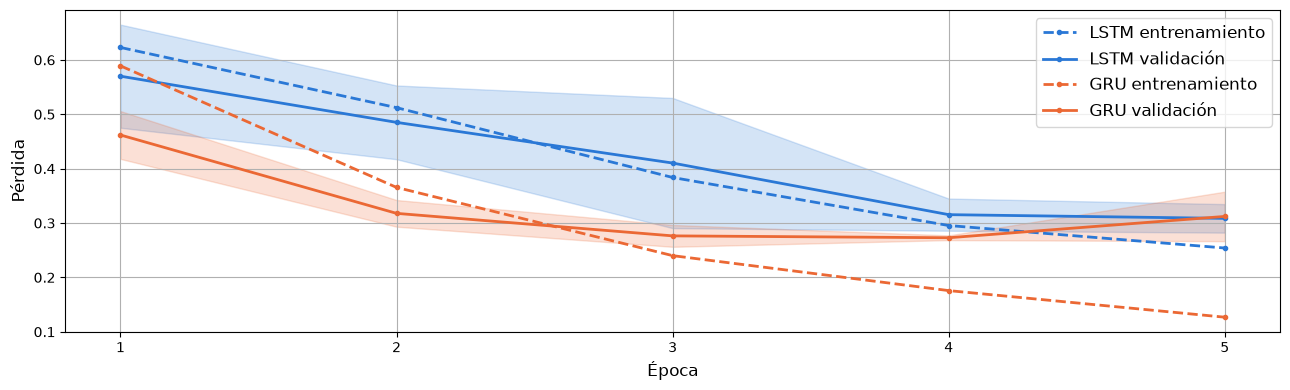

In [30]:
def visualization_seeds(curvas):
    '''
    Grafica el promedio de las pérdidas por época de cada arquitectura.
    La banda muestra ± 1 desviación estándar de la pérdida de validación entre semillas.
    '''
    colores = {"LSTM": "#2a78d6", "GRU": "#eb6834"}
    fig, axes = plt.subplots(1, 1, figsize=(13, 4))

    for tipo, color in colores.items():
        datos = curvas[curvas["Modelo"] == tipo].groupby("Época")
        media, desviacion = datos.mean(numeric_only=True), datos.std(numeric_only=True)
        epocas = media.index
        axes.plot(epocas, media["loss"], color=color, linestyle="--", marker=".",
                  label=f"{tipo} entrenamiento", lw=2)
        axes.plot(epocas, media["val_loss"], color=color, linestyle="-", marker=".",
                  label=f"{tipo} validación", lw=2)
        axes.fill_between(epocas, media["val_loss"] - desviacion["val_loss"],
                          media["val_loss"] + desviacion["val_loss"], color=color, alpha=0.2)

    axes.set_xlabel("Época", fontsize=12)
    axes.set_ylabel("Pérdida", fontsize=12)
    axes.set_xticks(sorted(curvas["Época"].unique()))
    axes.grid()
    axes.legend(fontsize=12, loc="upper right")
    plt.tight_layout()
    plt.show()


visualization_seeds(curvas)

## 5.2. Análisis de la comparación

La GRU fue más exacta y más estable que la LSTM: 0,8865 ± 0,0008 de exactitud frente a 0,8734 ± 0,0146. La LSTM varió entre 0,8565 (semilla 2) y 0,8827 (semilla 1), y la corrida principal de la sección 3, con 0,8664, cae dentro de ese rango. Con una sola semilla no habríamos sabido cuánto se aleja del promedio.

En las curvas, la GRU baja la pérdida más rápido. En la época 2 su pérdida de entrenamiento promedio ya es 0,366, frente a 0,512 en la LSTM. Desde la época 3 o 4 empieza a sobreajustar: la pérdida de entrenamiento sigue bajando y la de validación sube (con la semilla 1 pasa de 0,2749 a 0,3638 en la época 5). Como restauramos los pesos de la mejor época de validación, ese sobreajuste no llega a prueba. La LSTM todavía mejoraba en la época 5 con las semillas 0 y 2, así que 5 épocas no le alcanzan para converger, y con la semilla 2 su pérdida de validación saltó a 0,5484 en la época 3.

El sesgo hacia la etiqueta 1 de la corrida principal (53,6 % de predicciones positivas) tampoco se repite de forma sistemática: con las demás semillas la proporción quedó entre 49,2 % y 53,3 %.

Los minutos por corrida no sirven para comparar las arquitecturas, porque las corridas compartieron la máquina con otros procesos y sus tiempos variaron entre 6,5 y 20,1 minutos.